# 23｜边缘与纹理：看见细节

目标：区分零件边界、表面纹理和加工缺陷。Canny 找亮度变化处；局部标准差描述一个小窗口的亮度变化强弱；Gabor 滤波器响应某个方向的纹理。这些都不是“焊接强度计”。

参考：[OpenCV Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html)。本课在真实焊缝照片上计算派生特征。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


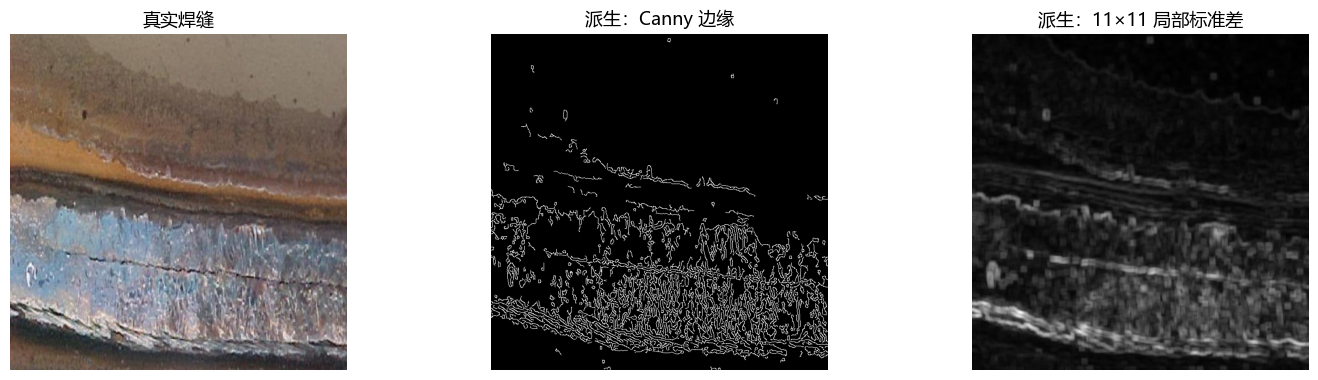

In [2]:
image = lab.load_case("weld_crack")
g = lab.gray(image)
smooth = cv2.GaussianBlur(g, (5, 5), 0)
edges = cv2.Canny(smooth, 40, 100)
std = lab.local_std(g, 11)
std_view = cv2.normalize(std, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
lab.show_images([image, edges, std_view],
                ["真实焊缝", "派生：Canny 边缘", "派生：11×11 局部标准差"], cols=3)

## 1. 方向纹理

Gabor 核的方向改变时，同一焊纹的响应会变化。这说明不能只靠一个固定方向阈值处理任意旋转。要么先对齐工件方向，要么显式考虑多个方向，并用真实例子检验。下方仅查看滤波响应，不训练分类器。

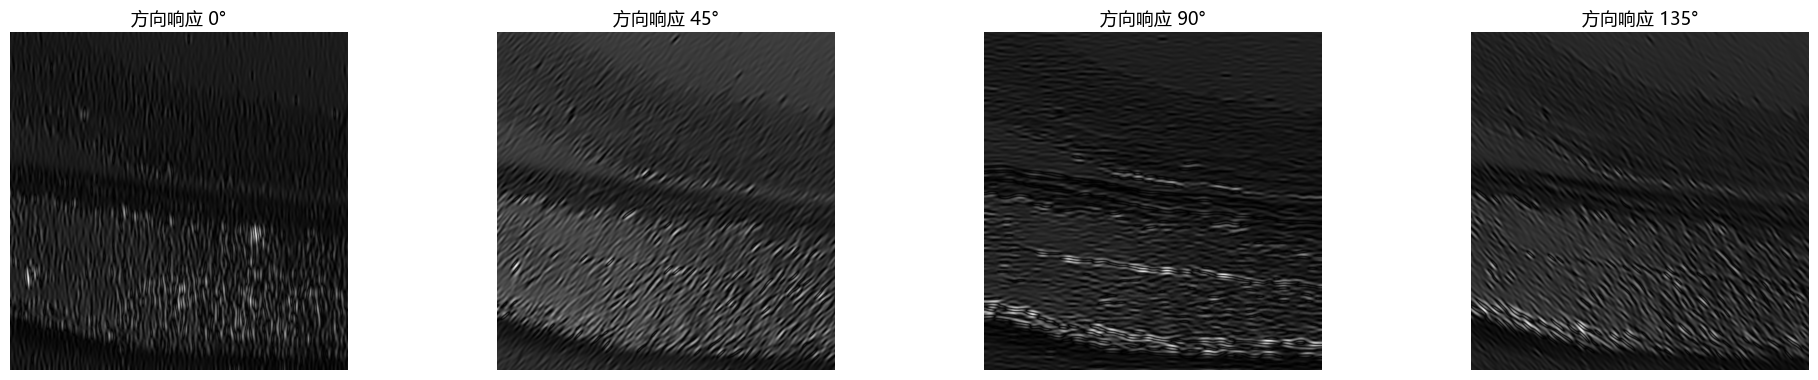

In [3]:
responses = []
angles = [0, 45, 90, 135]
for angle in angles:
    kernel = cv2.getGaborKernel((21, 21), 4.0, np.deg2rad(angle), 9.0, 0.6, 0, ktype=cv2.CV_32F)
    response = cv2.filter2D(g.astype(np.float32), cv2.CV_32F, kernel)
    responses.append(cv2.normalize(np.abs(response), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8))
lab.show_images(responses, [f"方向响应 {angle}°" for angle in angles], cols=4)

## 2. 光斑和噪声也会产生“纹理”

边缘密度只是边缘像素比例。把正常照片加噪声，会出现很多新的梯度。将这个结果直接当成“焊格数量”会出错。真实七格需要先定位镍片和焊纹区，再对齐、分格、判断可见性。

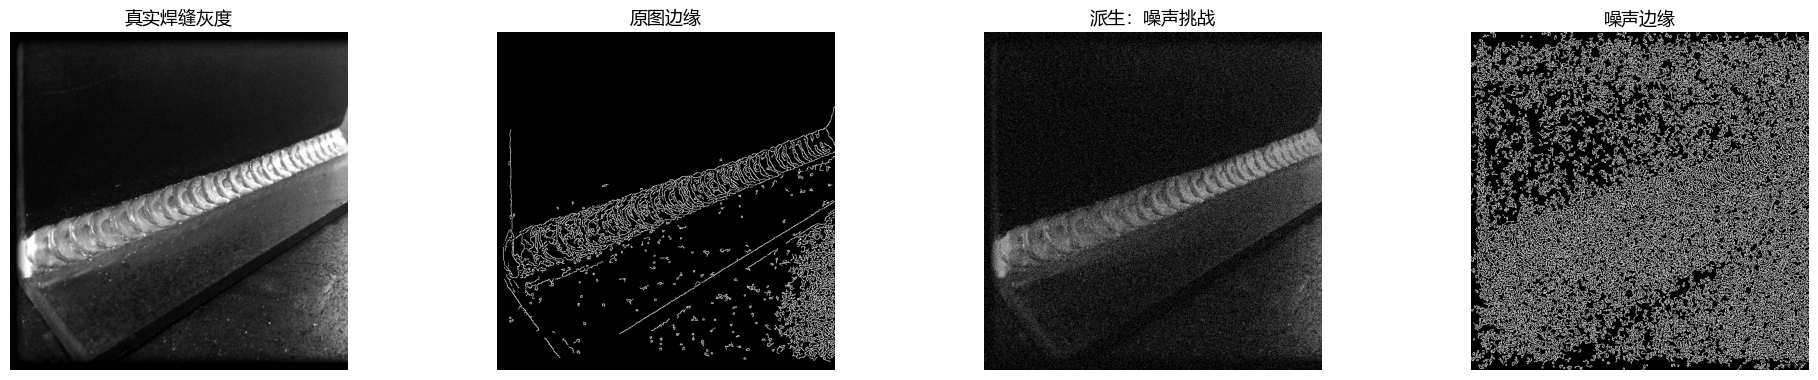

边缘密度，原图 / 派生噪声： 0.0563 0.2866


In [4]:
reference = lab.load_case("weld_good", grayscale=True)
noisy = lab.degrade(reference, 0.6, noise=25)
edge_ref = cv2.Canny(cv2.GaussianBlur(reference, (3, 3), 0), 40, 100)
edge_noise = cv2.Canny(cv2.GaussianBlur(noisy, (3, 3), 0), 40, 100)
lab.show_images([reference, edge_ref, noisy, edge_noise],
                ["真实焊缝灰度", "原图边缘", "派生：噪声挑战", "噪声边缘"], cols=4)
print("边缘密度，原图 / 派生噪声：", round(float(np.mean(edge_ref > 0)), 4), round(float(np.mean(edge_noise > 0)), 4))

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。